# Calibration of EKARUS: a pyramid WFS, and its deformable mirror.

Ekarus is a Pyramid-based AO system installed in the 1.82 m Copernico telescope in Asiago, Italy. It has an Alpao468 DM

The calibration procedure is as follows:
1. We load the data, and pre-process it to facilitate the calibration.
2. We make a first rough calibration to place the pupils in the correct positions
3. We calibrate the static amplitude and phase from the bench
4. We define the deformable mirror and perform a rough alignment to determine rotations, flips and signs
5. Using the fully differentiable WFS and DM models we fit all the degrees of freedom to compute the misregistration

In [1]:
import torch
device = 'cuda' if torch.cuda.is_available() else 'cpu'

from AI4AO import PyramidWFS, DeformableMirror, imshow, TwinCalibrator, PhaseDataset, imshow, imshow_multiple
from AI4AO.paths import DATA_DIR

from mmengine import Config
import numpy as np
import matplotlib.pyplot as plt

You can download the data to calibrate from here

[Link to files](https://nuage.osupytheas.fr/s/TFcmisncEPZ6JXd)

We load the bench interaction matrix, the modes-to-commands matrix `M2C`, and the valid-pixel map. The interaction matrix comes as a flat vector per valid pixel, so we scatter it back into a full detector-sized frame and crop it. We don't have a dedicated bench reference frame for EKARUS, so we use the valid-pixel map itself as a stand-in reference for the pupil positions.

In [2]:
ekarus_iMat = np.load(DATA_DIR / "Ekarus" / "IM.npy").T
ekarus_iMat = torch.from_numpy(ekarus_iMat.astype(np.float32)).to(device = device, dtype=torch.float32)

nModes = ekarus_iMat.shape[0]

M2C = np.load(DATA_DIR / "Ekarus" / "M2C_KL_OOPAO.npy")
M2C = torch.from_numpy(M2C).to(device = device, dtype = torch.float32)
M2C = M2C[:, :nModes]

valid_pix = np.load(DATA_DIR / "Ekarus" / "valid_pix_map.npy").astype(np.bool_)
W,H = valid_pix.shape
nPix = int(valid_pix.sum())

ekarus_iMat = ekarus_iMat[:,:nPix]

iMat = torch.zeros((nModes,W,H)).to(device = device, dtype=torch.float32)
iMat[:, valid_pix] = ekarus_iMat
iMat = iMat[:, 40:-60, 50:-50]

reference_frame = torch.from_numpy(valid_pix).to(device = device, dtype=torch.float32)
reference_frame /= reference_frame.sum()
reference_frame = reference_frame[40:-60, 50:-50]

In [3]:
paramfile = 'Ekarus_params.py'  # file of experimental parameters

# Config extraction

WFSParams = Config.fromfile(paramfile)['WFSParams']
WFSParams["centralObstruction"] = 0.
WFSParams["useNoise"] = False
WFSParams["Modulation"] = 3

DMParams = Config.fromfile(paramfile)['DMParams']

wfs = PyramidWFS(WFSParams, device)

calibrator = TwinCalibrator(wfs, dm=None, device=device)

## Pupil positioning

We start the calibration by placing the pupils in the correct positions, using `TwinCalibrator.fit_pupil_to_reference`. It:
1. Updates the position of the pupils with `wfs.BuildMask()`
2. Computes a reference intensity with `wfs.BuildReferenceIntensity()`
3. Compares it to the reference frame and backpropagates

It is possible that the pupils are not aligned on the first try and you can run the cell as many times as you need. Also, you can change `n_iter` to have more or less iterations, and `lr` to change the learning rate of the optimizer.

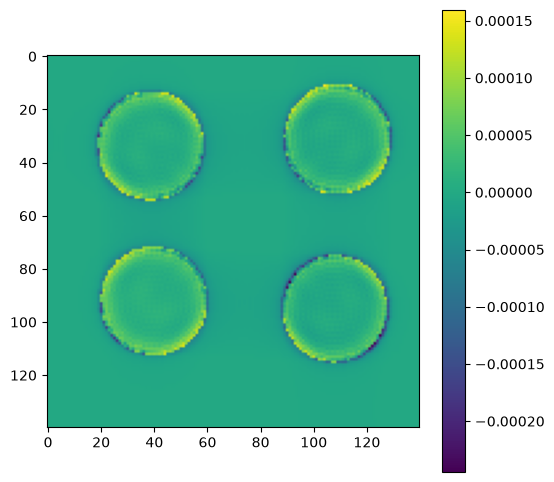

In [4]:
final_loss = calibrator.fit_pupil_to_reference(
    reference_frame,
    wfs.parameters(),
    lr=3e-3,
    n_iter=200,
)

## DM parameters

`moffatParam`: Corresponds to the moffat exponent which interpolates between a Cauchy and Gaussian shapes for the influence functions.

`signedAmplitude`: Amplitude in OPD of the DM. Can be positive or negative, depending on convention.

`Flips`: Flip left-right or top-bottom. If you don't know them, don't worry as there is a rough calibration step that can find the best configuration.

`misreg`: Dictionary containing the misregistrations of the DM. These are compatible with OOPAO's misreg.

If you don't know the correct flips, rotations, and sign of the DM, `calibrator.rough_calibrate_dm(bench_iMat, M2C)` performs an automatic selection of the best starting values.

In [5]:
DMParams = dict(
    {
        "Nactuator": 24,
        "Nmodes": 400,
        "IFType": 'tps',
        # "moffatParam": 2,
        "signedAmplitude": 0.3e-5,
        "MechCoupling": 0.36,
        "FlipLeftRight": True,
        "FlipTopBottom": True
    }
)

param = {}
param['rotationAngle'] = 0
# shift X in m
param['shiftX'] = 0
# shift Y in m
param['shiftY'] = 0
# amamorphosis angle in degrees
param['anamorphosisAngle'] = 0
# normal scaling in % of diameter
param['tangentialScaling'] = 0
# radial scaling in % of diameter
param['radialScaling'] = 0

dm = DeformableMirror(WFSParams,
                    DMParams,
                    per_actuator_calibration=True,
                    device=device,
                    misreg=param)

calibrator.dm = dm
calibrator.rough_calibrate_dm(iMat, M2C)


Total number of actuators: 468


Best configuration found to be: 
Rotation angle: 90.0
Sign: Possitive
Flip left-right: False
Flip top-bottom: True

Updating values in the DM


We define the static amplitude and phase maps for the bench. These will get optimized along with the misreg of the DM. To avoid overfitting or falling into local minima, the training is set such that these maps are not updated at the beginning and slowly start getting more and more importance as the optimization progresses.

Always check on some modes to see if the rough alignment makes sense! You can change `idx` to see through some modes.

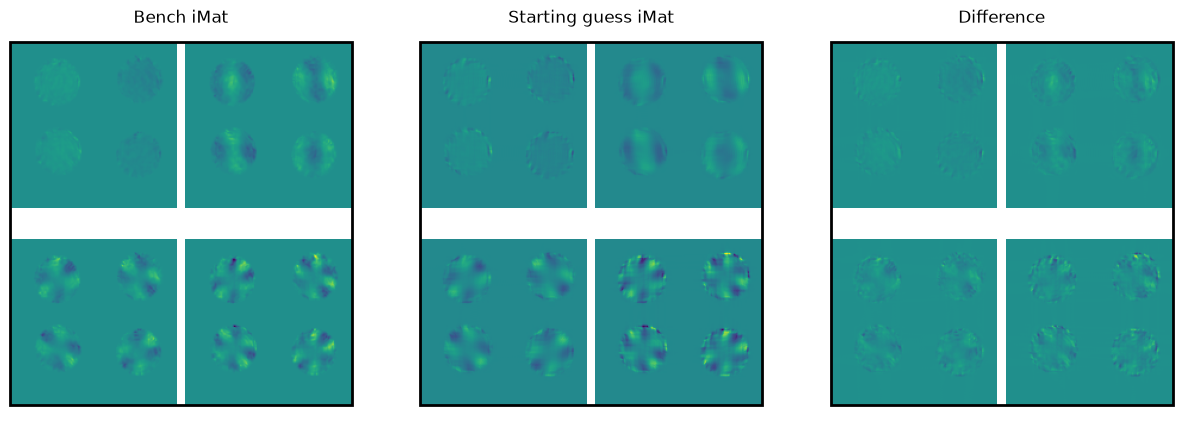

In [6]:
index = list(range(0,400,5))

calibrator.sanity_check_plot(iMat, M2C, index, idx=4)

## Optimization of misregistration, WFS parameters and static amplitude and phase

We define the optimization problem to be: find the best parameters for the DM, WFS and offsets to produce a synthetic interaction matrix as close as possible to the one measured on the bench, using `calibrator.fit_dm_and_offsets`.

Given that the main parameters to be trained are the DM's, the learning rate is set higher than for the WFS, which was previously optimized. For the static amplitude and phase, to avoid overfitting, the optimization starts with an extremely low learning rate for them, so the optimizer prioritizes changing the parameters of the DM and WFS first. The learning rate for the offsets is then gradually increased to match that of the DM and WFS.

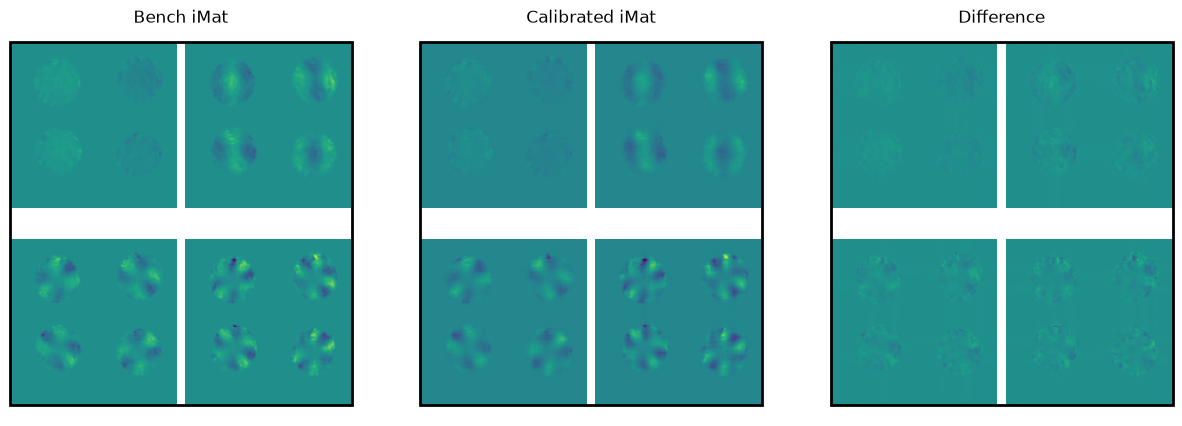

########################################
loss = 0.11499
########################################
({'rotationAngle': 88.63606262207031, 'shiftX': -0.018745637968182564, 'shiftY': -0.0032930719703435896, 'anamorphosisAngle': 3.0205929279327393, 'tangentialScaling': -2.663932181894779, 'radialScaling': -0.4747518803924322}, {'moffatParam': 2.0, 'signedAmplitude': 2.700363211260992e-06, 'MechCoupling': 0.4675414562225342, 'IFType': 'tps', 'FlipLeftRight': False, 'FlipTopBottom': True, 'offset_to_fit_number_of_actuators': 0.2})


In [7]:
final_loss, original_positons, transformed_positons = calibrator.fit_dm_and_offsets(
    iMat,
    M2C,
    index,
    n_iter=300,
    lr_dm=1e-2,
    lr_wfs=1e-2,
    fit_static_offsets=True,
    plot_mode_idx=4,
)

You can check the retrieved actuator positions, the static amplitude and phase values.

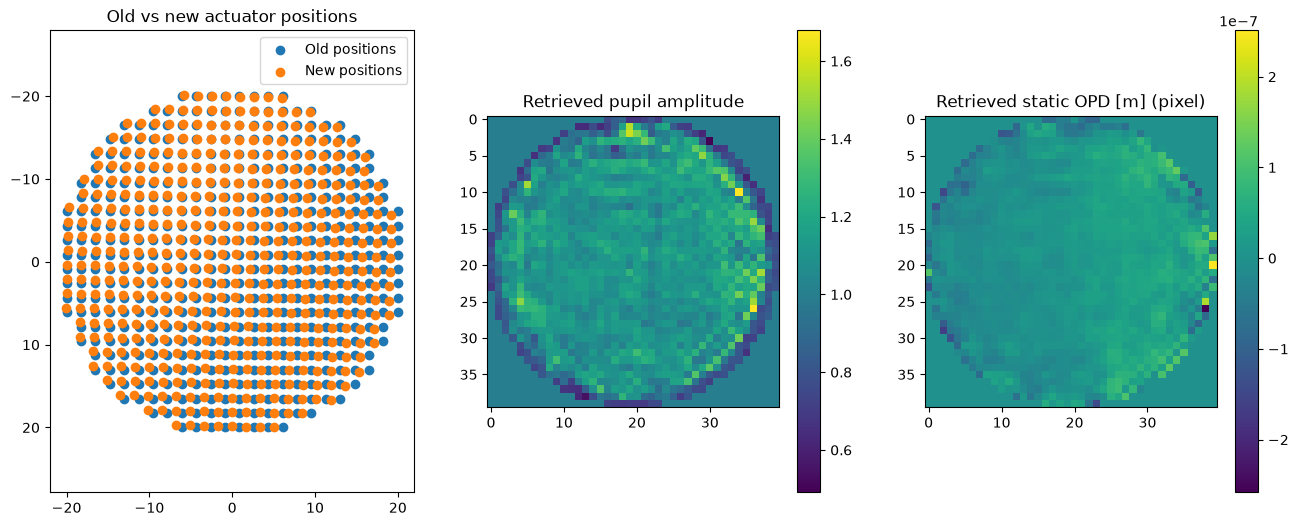

In [8]:
calibrator.plot_actuator_and_offsets(original_positons, transformed_positons)

<>:14: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:14: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/tmp/ipykernel_2444706/646675397.py:14: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  {"tensor": amplitudes * 1e6, "title": "Actuator unitary amplitude ($\mu m$)"},


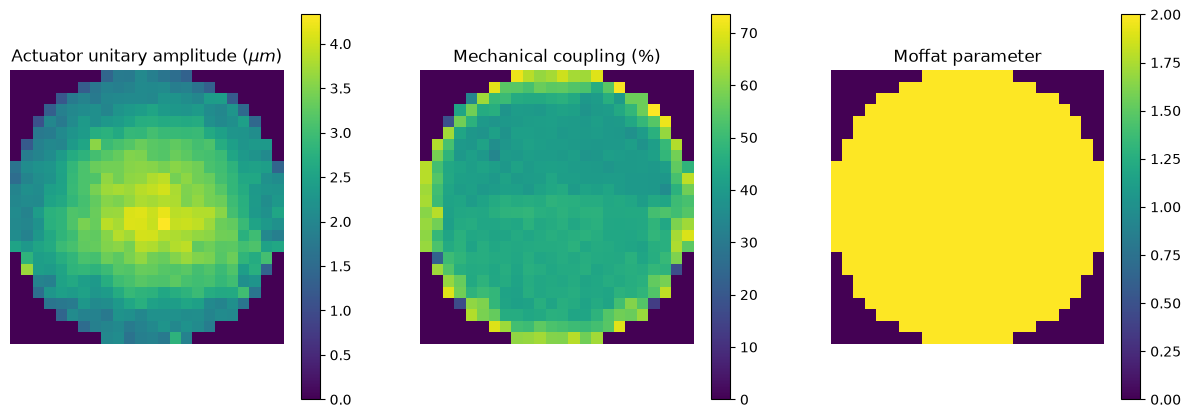

<Figure size 640x480 with 0 Axes>

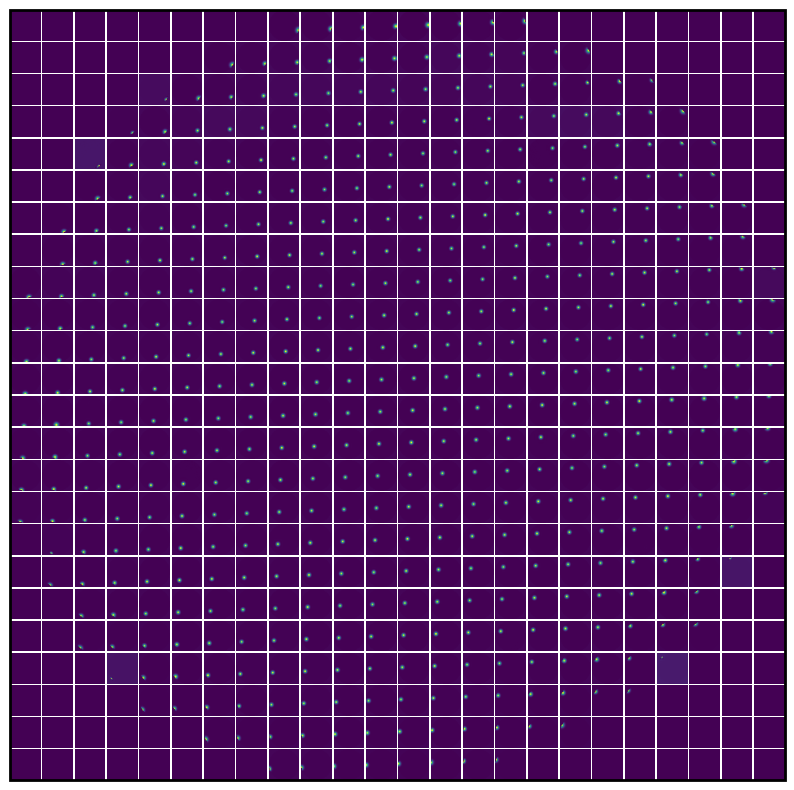

In [ ]:
amplitudes = torch.zeros((dm.Nact, dm.Nact), device = device, dtype=torch.float32)
coupling = torch.zeros_like(amplitudes)
moffat_parameters = torch.zeros_like(amplitudes)

amplitudes[dm.grid] = dm.sign
coupling[dm.grid] = dm.mechCoupling
moffat_parameters[dm.grid] = dm.moffatParameter

IFs = torch.zeros((dm.Nact**2, dm.Nres, dm.Nres), device = device, dtype=torch.float32)
IFs[dm.grid.flatten()] = dm.IF

imshow_multiple(
[
    {"tensor": amplitudes * 1e6, "title": "Actuator unitary amplitude ($\mu m$)"},
    {"tensor": coupling * 100, "title": "Mechanical coupling (%)"},
    # {"tensor": moffat_parameters, "title": "Moffat parameter"}
],
colorbar=True
)
plt.show()

plt.figure()
imshow(IFs, figsize=(10,10))
plt.show()

We now compute a new interaction matrix with the fitted parameters.

You can change the index to see how well the algorithm worked to fit the parameters.

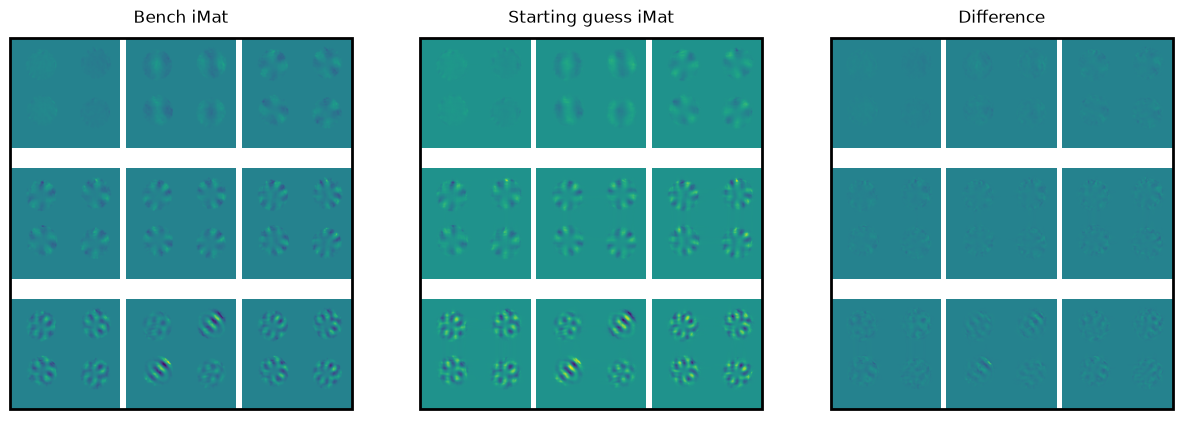

In [15]:
calibrator.sanity_check_plot(iMat, M2C, index, idx=9)

Total number of actuators: 468


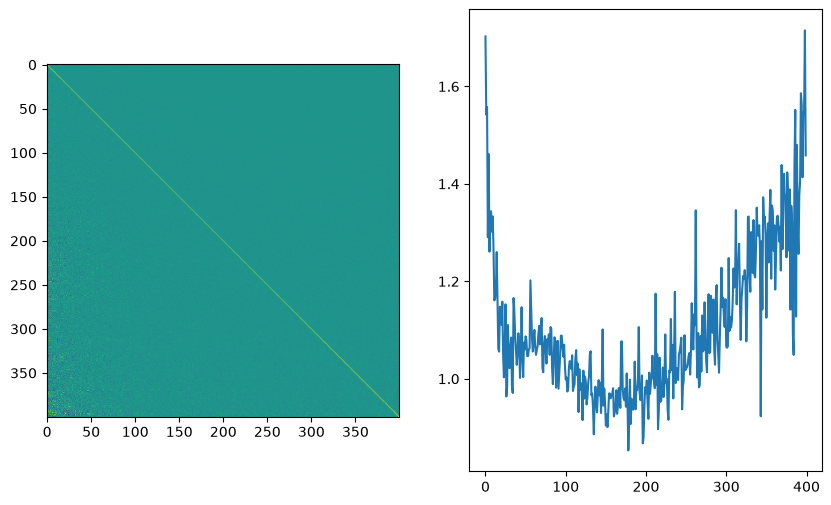

In [11]:
modes = calibrator.rebuild_reconstruction_matrix(M2C)
cov = calibrator.crosstalk_diagnostic(iMat)

In [12]:
PATH_WFS, PATH_DM = calibrator.save("Ekarus")

Total number of actuators: 468
Total number of actuators: 468


Total number of actuators: 468
Total number of actuators: 468


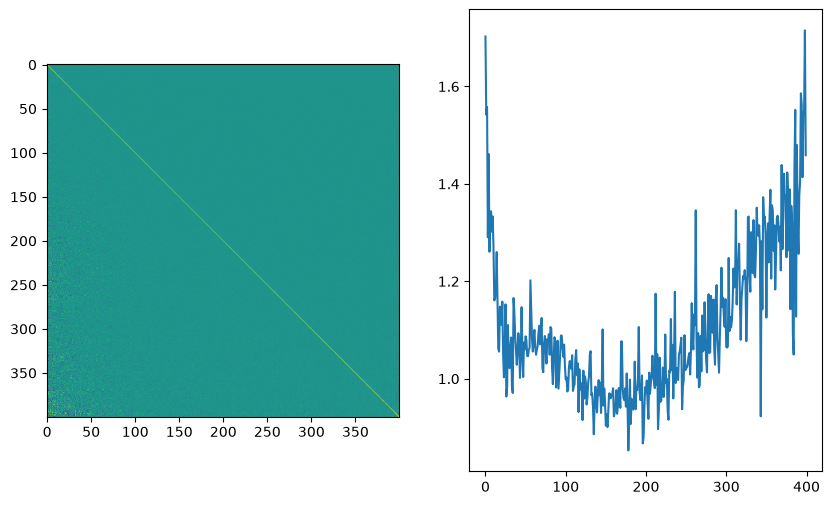

In [13]:
wfs = PyramidWFS(WFSParams, device)
dm = DeformableMirror(WFSParams,
                    DMParams,
                    device=device)

calibrator.wfs = wfs
calibrator.dm = dm
calibrator.load("Ekarus")

modes = calibrator.rebuild_reconstruction_matrix(M2C)
cov = calibrator.crosstalk_diagnostic(iMat)

## Check the quality of the digital twin

To check how accurate the digital twin compares to the bench, a useful test is to close the loop in simulation with the bench interaction matrix. To do so, we will generate phase screen, filter the high frequencies and close the loop with the bench iMat. In the perfect scenario the residual OPD should be zero (reason why we filter the high frequencies). Any deviation will highlight uncorrected misregistrations.


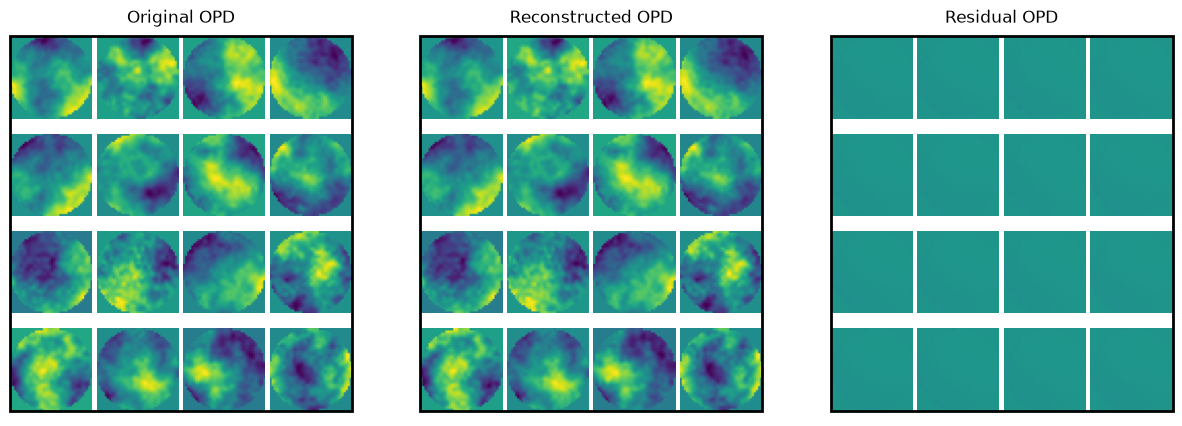

In [ ]:
AtmosParams = Config.fromfile(paramfile)['AtmosParams']
LoopParams = Config.fromfile(paramfile)['LoopParams']
WFSParams['Nphotons'] = [6,6]
WFSParams['RON'] = [0,0]
WFSParams['useNoise'] = False
dataset = PhaseDataset(WFSParams, AtmosParams, LoopParams, DMParams, device)
dataset.generateClosedLoop = True

modes = dm(M2C.T)
oracle_reconstructor = torch.linalg.pinv(modes.flatten(start_dim = -2))
bench_reconstructor = M2C @ torch.linalg.pinv(iMat.flatten(start_dim = -2).T)

batch = dataset[0]
opd = batch["opd"]
modal_coefficients = opd.flatten(start_dim = -2) @ oracle_reconstructor

filtered_opd = dm((modal_coefficients @ M2C.T))

n_iter = 100
gain = 0.1
coeffs = 0
residual_opd = torch.clone(filtered_opd)

for i in range(n_iter):
    wfs_signal = wfs(residual_opd)
    coeffs = coeffs + gain * wfs_signal.flatten(start_dim = -2) @ bench_reconstructor.T
    reconstructed_opd = dm(coeffs)
    residual_opd = filtered_opd - reconstructed_opd
imshow_multiple(
[
    {"tensor": filtered_opd, "title": "Original OPD"},
    {"tensor": reconstructed_opd, "title": "Reconstructed OPD"},
    {"tensor": residual_opd, "title": "Residual OPD", "scale_reference": filtered_opd}
]
)
plt.show()
